# Customer Churn Analytics Platform
## 06 — Churn Analysis

**Objective:**  
Identify the customer segments and behavioral patterns associated with higher churn rates and translate analytical findings into actionable retention opportunities.

### Analysis Goals
- Quantify the overall churn level
- Identify high-churn customer segments
- Compare churn rates across contract types
- Analyze churn across customer tenure
- Evaluate the relationship between monthly charges and churn
- Analyze payment behavior
- Evaluate internet service and support characteristics
- Investigate service adoption and customer engagement
- Identify combinations of factors associated with elevated churn
- Prioritize customer segments for retention actions
- Translate findings into business recommendations

In [ ]:
# ============================================================
# IMPORT LIBRARIES
# ============================================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [ ]:
# ============================================================
# VISUALIZATION THEME
# ============================================================

plt.style.use("dark_background")

sns.set_theme(
    style="darkgrid",
    context="notebook"
)

DARK_BG = "#0F172A"
CARD_BG = "#1E293B"
TEXT_COLOR = "#F8FAFC"
GRID_COLOR = "#334155"

ACTIVE_COLOR = "#216F3F"
CHURN_COLOR = "#A1343C"
DARK_BLUE = "#1F4E78"

plt.rcParams.update({
    "figure.facecolor": DARK_BG,
    "axes.facecolor": CARD_BG,
    "axes.edgecolor": GRID_COLOR,
    "axes.labelcolor": TEXT_COLOR,
    "axes.titlecolor": TEXT_COLOR,
    "xtick.color": TEXT_COLOR,
    "ytick.color": TEXT_COLOR,
    "grid.color": GRID_COLOR,
    "text.color": TEXT_COLOR,
    "figure.titlesize": 16,
    "axes.titlesize": 14,
    "axes.labelsize": 11
})

print("Visualization theme configured.")

Visualization theme configured.


In [ ]:
# ============================================================
# LOAD FEATURE DATASET
# ============================================================

DATA_PATH = Path(
    "../data/processed/customer_churn_features.csv"
)

df = pd.read_csv(DATA_PATH)

print("Feature-engineered dataset loaded successfully.")
print(f"Rows    : {df.shape[0]:,}")
print(f"Columns : {df.shape[1]:,}")

Feature-engineered dataset loaded successfully.
Rows    : 7,043
Columns : 37


In [ ]:
# ============================================================
# INITIAL VALIDATION
# ============================================================

print("Missing values :", df.isna().sum().sum())
print("Duplicate rows :", df.duplicated().sum())
print("Unique customers:", df["customerid"].nunique())

Missing values : 0
Duplicate rows : 0
Unique customers: 7043


In [ ]:
# ============================================================
# OVERALL CHURN KPI
# ============================================================

total_customers = len(df)

churned_customers = int(
    df["churn_flag"].sum()
)

active_customers = int(
    df["active_flag"].sum()
)

overall_churn_rate = (
    churned_customers / total_customers * 100
)

print("CUSTOMER CHURN OVERVIEW")
print("-" * 45)

print(f"Total Customers  : {total_customers:,}")
print(f"Active Customers : {active_customers:,}")
print(f"Churned Customers: {churned_customers:,}")
print(f"Churn Rate       : {overall_churn_rate:.2f}%")

CUSTOMER CHURN OVERVIEW
---------------------------------------------
Total Customers  : 7,043
Active Customers : 5,174
Churned Customers: 1,869
Churn Rate       : 26.54%


In [ ]:
# ============================================================
# CUSTOMER CHURN BY CONTRACT
# ============================================================

contract_churn = (
    df.groupby(
        ["contract", "churn"],
        observed=False
    )
    .size()
    .reset_index(name="Customers")
)

contract_churn

,contract,churn,Customers
0,Month-to-month,no,2220
1,Month-to-month,yes,1655
2,One year,no,1307
3,One year,yes,166
4,Two year,no,1647
5,Two year,yes,48


In [ ]:
# ============================================================
# CHURN RATE BY CONTRACT
# ============================================================
contract_rate = (
    df.groupby(
        "contract",
        observed=False
    )["churn_flag"]
    .agg(
        Customers="count",
        Churned_Customers="sum",
        Churn_Rate="mean"
    )
)

contract_rate["Churn_Rate"] = (
    contract_rate["Churn_Rate"] * 100
).round(2)

contract_rate = contract_rate.sort_values(
    "Churn_Rate",
    ascending=False
)

contract_rate

,Customers,Churned_Customers,Churn_Rate
contract,,,
Month-to-month,3875,1655,42.71
One year,1473,166,11.27
Two year,1695,48,2.83


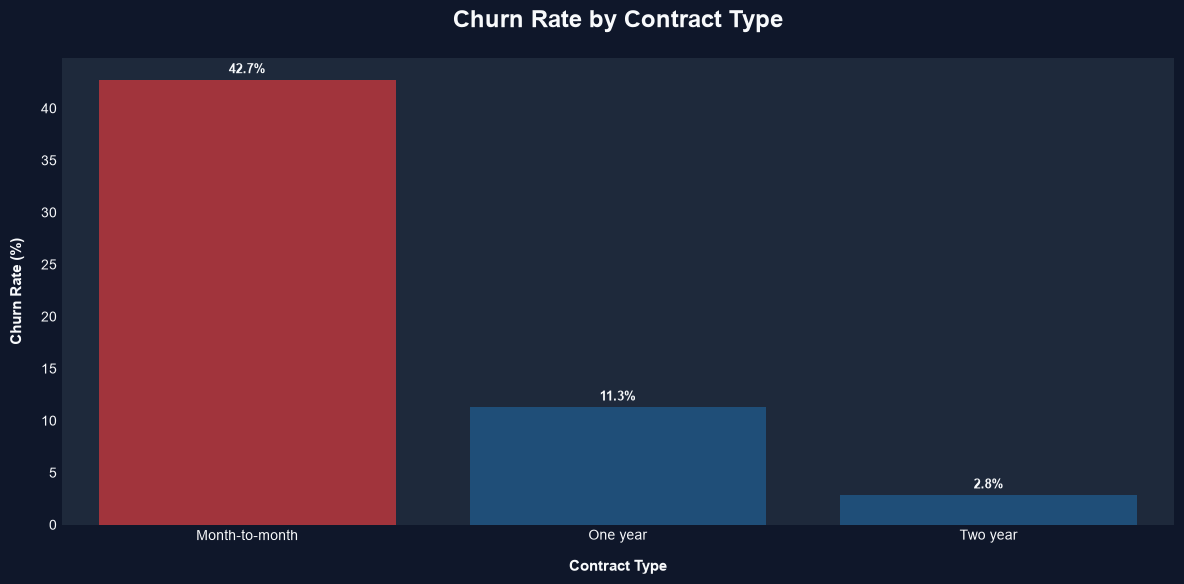

In [ ]:
# ============================================================
# CHURN RATE BY CONTRACT
# Professional Portfolio Visualization
# ============================================================

contract_rate_plot = contract_rate.reset_index()

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=contract_rate_plot,
    x="contract",
    y="Churn_Rate",
    color=DARK_BLUE,
    edgecolor="none"
)

# Highlight highest churn rate
max_position = contract_rate_plot["Churn_Rate"].idxmax()

for i, bar in enumerate(ax.patches):
    if i == max_position:
        bar.set_facecolor(CHURN_COLOR)
    else:
        bar.set_facecolor(DARK_BLUE)

ax.set_title(
    "Churn Rate by Contract Type",
    fontsize=17,
    fontweight="bold",
    pad=22
)

ax.set_xlabel(
    "Contract Type",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

ax.set_ylabel(
    "Churn Rate (%)",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(
    axis="both",
    length=0,
    labelsize=10
)

ax.bar_label(
    ax.containers[0],
    fmt="%.1f%%",
    padding=3,
    fontsize=9,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

### Business Insight

Month-to-month customers represent the highest churn-risk contract segment, indicating that customers without long-term commitment require stronger retention and conversion strategies.

In [10]:
# ============================================================
# CHURN RATE BY TENURE
# ============================================================

tenure_churn = (
    df.groupby(
        ["tenure_group", "churn"],
        observed=False
    )
    .size()
    .reset_index(name="Customers")
)

tenure_churn

,tenure_group,churn,Customers
0,0-12 Months,no,1149
1,0-12 Months,yes,1037
2,13-24 Months,no,730
3,13-24 Months,yes,294
4,25-48 Months,no,1269
5,25-48 Months,yes,325
6,49-72 Months,no,2026
7,49-72 Months,yes,213


In [ ]:
# ============================================================
# TENURE CHURN RATE
# ============================================================

tenure_rate = (
    df.groupby(
        "tenure_group",
        observed=False
    )["churn_flag"]
    .agg(
        Customers="count",
        Churned_Customers="sum",
        Churn_Rate="mean"
    )
)

tenure_rate["Churn_Rate"] *= 100

tenure_order = [
    "0–12 Months",
    "13–24 Months",
    "25–48 Months",
    "49–72 Months"
]

tenure_rate = tenure_rate.reindex(
    tenure_order
)

tenure_rate

,Customers,Churned_Customers,Churn_Rate
tenure_group,,,
0–12 Months,NaN,NaN,NaN
13–24 Months,NaN,NaN,NaN
25–48 Months,NaN,NaN,NaN
49–72 Months,NaN,NaN,NaN


## MONTHLY CHARGES
### Business Question

Does a higher monthly charge correspond to a higher churn rate

In [ ]:
# ============================================================
# CHURN BY MONTHLY CHARGES
# ============================================================

monthly_charges_churn = (
    df.groupby(
        ["monthly_charges_group", "churn"],
        observed=False
    )
    .size()
    .reset_index(name="Customers")
)

monthly_charges_churn

,monthly_charges_group,churn,Customers
0,High,no,1577
1,High,yes,809
2,Low,no,1491
3,Low,yes,162
4,Medium,no,937
5,Medium,yes,328
6,Very High,no,1169
7,Very High,yes,570


In [ ]:
# ============================================================
# CHURN RATE BY MONTHLY CHARGES
# ============================================================

charges_rate = (
    df.groupby(
        "monthly_charges_group",
        observed=False
    )["churn_flag"]
    .agg(
        Customers="count",
        Churned_Customers="sum",
        Churn_Rate="mean"
    )
)

charges_rate["Churn_Rate"] *= 100

charges_rate

,Customers,Churned_Customers,Churn_Rate
monthly_charges_group,,,
High,2386,809,33.906119
Low,1653,162,9.800363
Medium,1265,328,25.928854
Very High,1739,570,32.777458


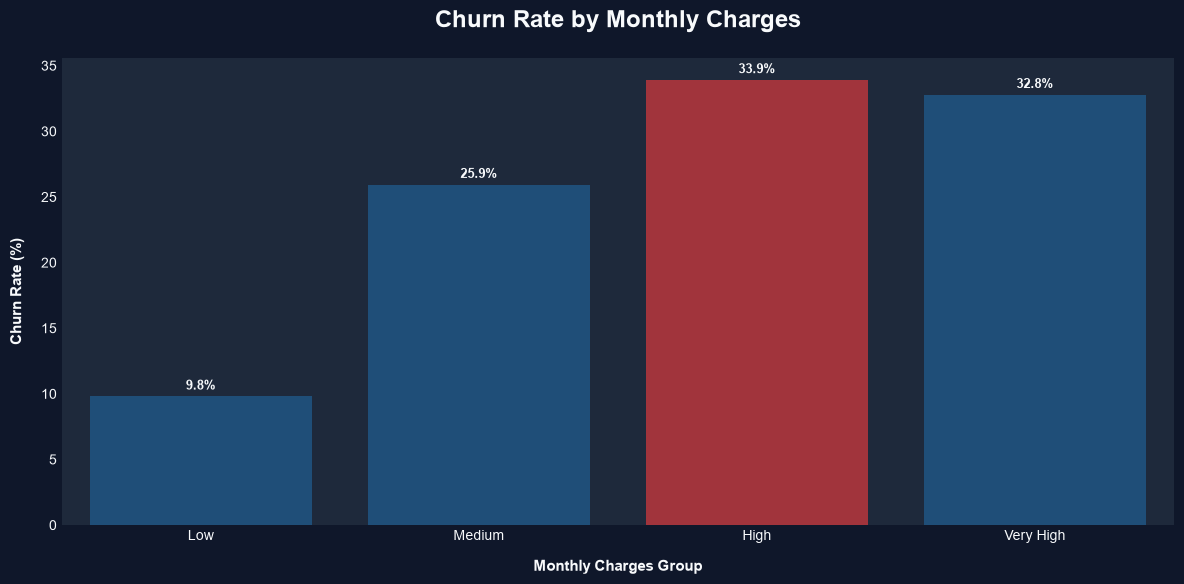

In [ ]:
# ============================================================
# CHURN RATE BY MONTHLY CHARGES
# Professional Portfolio Visualization
# ============================================================

charges_rate_plot = charges_rate.reset_index()

charge_order = [
    "Low",
    "Medium",
    "High",
    "Very High"
]

charges_rate_plot["monthly_charges_group"] = pd.Categorical(
    charges_rate_plot["monthly_charges_group"],
    categories=charge_order,
    ordered=True
)

charges_rate_plot = charges_rate_plot.sort_values(
    "monthly_charges_group"
)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=charges_rate_plot,
    x="monthly_charges_group",
    y="Churn_Rate",
    color=DARK_BLUE,
    edgecolor="none"
)

max_position = charges_rate_plot["Churn_Rate"].idxmax()

for i, (_, row) in enumerate(
    charges_rate_plot.iterrows()
):
    if row["Churn_Rate"] == charges_rate_plot["Churn_Rate"].max():
        ax.patches[i].set_facecolor(CHURN_COLOR)
    else:
        ax.patches[i].set_facecolor(DARK_BLUE)

ax.set_title(
    "Churn Rate by Monthly Charges",
    fontsize=17,
    fontweight="bold",
    pad=22
)

ax.set_xlabel(
    "Monthly Charges Group",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

ax.set_ylabel(
    "Churn Rate (%)",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(
    axis="both",
    length=0,
    labelsize=10
)

ax.bar_label(
    ax.containers[0],
    fmt="%.1f%%",
    padding=3,
    fontsize=9,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

## CHURN RATE BY PAYMENT METHOD 
### Business Question

Which payment method is associated with the highest churn rate

In [ ]:
# ============================================================
# CHURN RATE BY PAYMENT METHOD
# ============================================================

payment_rate = (
    df.groupby(
        "paymentmethod"
    )["churn_flag"]
    .agg(
        Customers="count",
        Churned_Customers="sum",
        Churn_Rate="mean"
    )
)

payment_rate["Churn_Rate"] *= 100

payment_rate = payment_rate.sort_values(
    "Churn_Rate",
    ascending=False
)

payment_rate

,Customers,Churned_Customers,Churn_Rate
paymentmethod,,,
Electronic check,2365,1071,45.285412
Mailed check,1612,308,19.106700
Bank transfer (automatic),1544,258,16.709845
Credit card (automatic),1522,232,15.243101


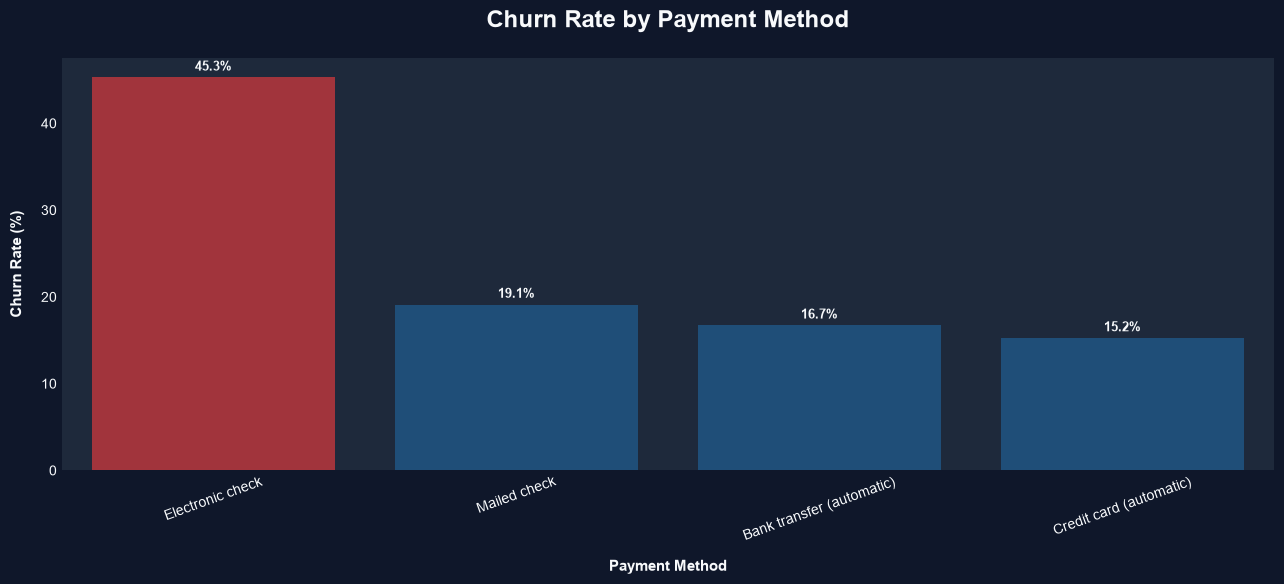

In [ ]:
# ============================================================
# CHURN RATE BY PAYMENT METHOD
# Professional Portfolio Visualization
# ============================================================

payment_rate_plot = payment_rate.reset_index()

plt.figure(figsize=(13, 6))

ax = sns.barplot(
    data=payment_rate_plot,
    x="paymentmethod",
    y="Churn_Rate",
    color=DARK_BLUE,
    edgecolor="none"
)

max_position = payment_rate_plot["Churn_Rate"].idxmax()

for i, (_, row) in enumerate(
    payment_rate_plot.iterrows()
):
    if row["Churn_Rate"] == payment_rate_plot["Churn_Rate"].max():
        ax.patches[i].set_facecolor(CHURN_COLOR)
    else:
        ax.patches[i].set_facecolor(DARK_BLUE)

ax.set_title(
    "Churn Rate by Payment Method",
    fontsize=17,
    fontweight="bold",
    pad=22
)

ax.set_xlabel(
    "Payment Method",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

ax.set_ylabel(
    "Churn Rate (%)",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

ax.tick_params(
    axis="x",
    rotation=20,
    length=0,
    labelsize=10
)

ax.tick_params(
    axis="y",
    length=0,
    labelsize=10
)

ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.bar_label(
    ax.containers[0],
    fmt="%.1f%%",
    padding=3,
    fontsize=9,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

## INTERNET SERVICE CHURN RATE
### Business Question

How does internet service type relate to customer churn?

In [20]:
# ============================================================
# CHURN RATE BY INTERNET SERVICE
# ============================================================

internet_rate = (
    df.groupby(
        "internetservice"
    )["churn_flag"]
    .agg(
        Customers="count",
        Churned_Customers="sum",
        Churn_Rate="mean"
    )
)

internet_rate["Churn_Rate"] *= 100

internet_rate = internet_rate.sort_values(
    "Churn_Rate",
    ascending=False
)

internet_rate

,Customers,Churned_Customers,Churn_Rate
internetservice,,,
Fiber optic,3096,1297,41.892765
DSL,2421,459,18.959108
No,1526,113,7.404980


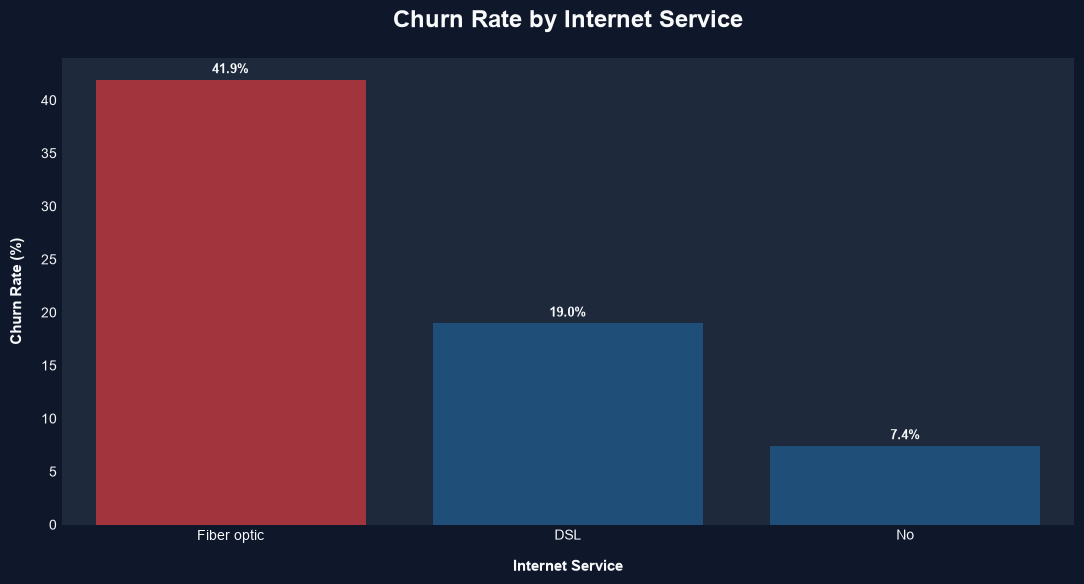

In [ ]:
# ============================================================
# CHURN RATE BY INTERNET SERVICE
# Professional Portfolio Visualization
# ============================================================

internet_rate_plot = internet_rate.reset_index()

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=internet_rate_plot,
    x="internetservice",
    y="Churn_Rate",
    color=DARK_BLUE,
    edgecolor="none"
)

for i, (_, row) in enumerate(
    internet_rate_plot.iterrows()
):
    if row["Churn_Rate"] == internet_rate_plot["Churn_Rate"].max():
        ax.patches[i].set_facecolor(CHURN_COLOR)
    else:
        ax.patches[i].set_facecolor(DARK_BLUE)

ax.set_title(
    "Churn Rate by Internet Service",
    fontsize=17,
    fontweight="bold",
    pad=22
)

ax.set_xlabel(
    "Internet Service",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

ax.set_ylabel(
    "Churn Rate (%)",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(
    axis="both",
    length=0,
    labelsize=10
)

ax.bar_label(
    ax.containers[0],
    fmt="%.1f%%",
    padding=3,
    fontsize=9,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

## SECURITY & SUPPORT
### Business Question

Are customers without security or technical support more exposed to churn?

In [ ]:
# ============================================================
# SECURITY & SUPPORT ANALYSIS
# ============================================================

security_support_rate = (
    df.groupby(
        "security_support_count"
    )["churn_flag"]
    .agg(
        Customers="count",
        Churned_Customers="sum",
        Churn_Rate="mean"
    )
)

security_support_rate["Churn_Rate"] *= 100

security_support_rate

,Customers,Churned_Customers,Churn_Rate
security_support_count,,,
0,2793,831,29.752954
1,1467,570,38.854806
2,1372,326,23.760933
3,941,117,12.433581
4,470,25,5.319149


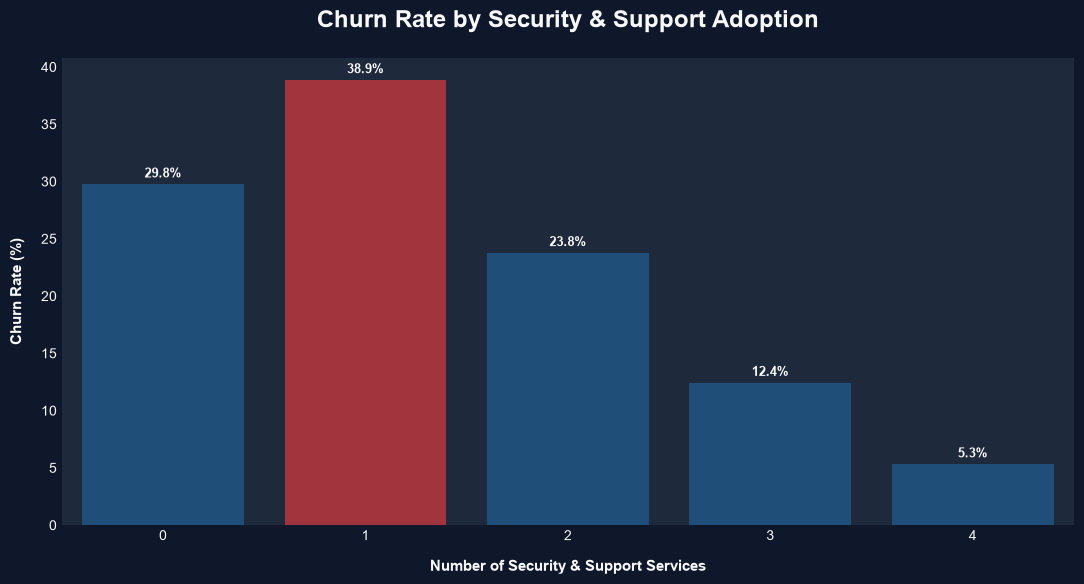

In [ ]:
# ============================================================
# CHURN RATE BY SECURITY & SUPPORT SERVICES
# Professional Portfolio Visualization
# ============================================================

support_plot = security_support_rate.reset_index()

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=support_plot,
    x="security_support_count",
    y="Churn_Rate",
    color=DARK_BLUE,
    edgecolor="none"
)

for i, (_, row) in enumerate(
    support_plot.iterrows()
):
    if row["Churn_Rate"] == support_plot["Churn_Rate"].max():
        ax.patches[i].set_facecolor(CHURN_COLOR)
    else:
        ax.patches[i].set_facecolor(DARK_BLUE)

ax.set_title(
    "Churn Rate by Security & Support Adoption",
    fontsize=17,
    fontweight="bold",
    pad=22
)

ax.set_xlabel(
    "Number of Security & Support Services",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

ax.set_ylabel(
    "Churn Rate (%)",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(
    axis="both",
    length=0,
    labelsize=10
)

ax.bar_label(
    ax.containers[0],
    fmt="%.1f%%",
    padding=3,
    fontsize=9,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

## SERVICE COUNT
### Business Question

Does broader service adoption correspond to lower churn?

In [25]:
# ============================================================
# CHURN RATE BY SERVICE COUNT
# ============================================================

service_rate = (
    df.groupby(
        "service_count"
    )["churn_flag"]
    .agg(
        Customers="count",
        Churned_Customers="sum",
        Churn_Rate="mean"
    )
)

service_rate["Churn_Rate"] *= 100

service_rate

,Customers,Churned_Customers,Churn_Rate
service_count,,,
0,80,35,43.750000
1,2253,488,21.660009
2,996,433,43.473896
3,1041,361,34.678194
4,1062,289,27.212806
5,827,182,22.007255
6,525,66,12.571429
7,259,15,5.791506


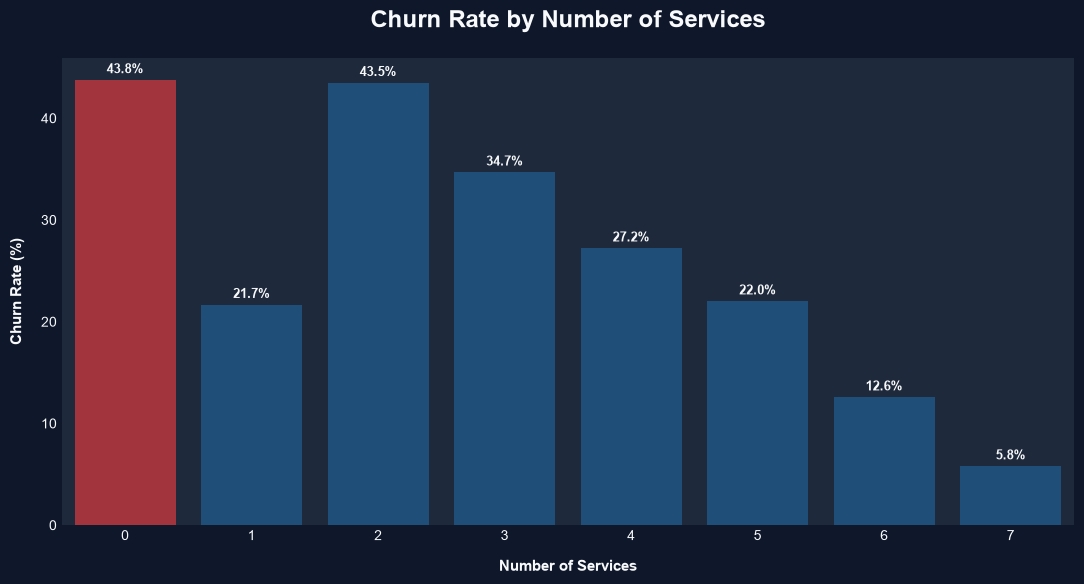

In [ ]:
# ============================================================
# CHURN RATE BY SERVICE COUNT
# Professional Portfolio Visualization
# ============================================================

service_plot = service_rate.reset_index()

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=service_plot,
    x="service_count",
    y="Churn_Rate",
    color=DARK_BLUE,
    edgecolor="none"
)

for i, (_, row) in enumerate(
    service_plot.iterrows()
):
    if row["Churn_Rate"] == service_plot["Churn_Rate"].max():
        ax.patches[i].set_facecolor(CHURN_COLOR)
    else:
        ax.patches[i].set_facecolor(DARK_BLUE)

ax.set_title(
    "Churn Rate by Number of Services",
    fontsize=17,
    fontweight="bold",
    pad=22
)

ax.set_xlabel(
    "Number of Services",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

ax.set_ylabel(
    "Churn Rate (%)",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(
    axis="both",
    length=0,
    labelsize=10
)

ax.bar_label(
    ax.containers[0],
    fmt="%.1f%%",
    padding=3,
    fontsize=9,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# CHURN RATE BY CUSTOMER SEGMENT
# ============================================================

senior_rate = (
    df.groupby(
        "seniorcitizen_label"
    )["churn_flag"]
    .agg(
        Customers="count",
        Churned_Customers="sum",
        Churn_Rate="mean"
    )
)

senior_rate["Churn_Rate"] *= 100

senior_rate

,Customers,Churned_Customers,Churn_Rate
seniorcitizen_label,,,
Non-Senior,5901,1393,23.606168
Senior Citizen,1142,476,41.681261


## MULTI-FACTOR CHURN ANALYSIS
### Business Question

Which combination of contract and tenure characteristics identifies the highest-risk customer segments?

In [28]:
# ============================================================
# MULTI-FACTOR CHURN ANALYSIS
# ============================================================

segment_analysis = (
    df.groupby(
        ["contract", "tenure_group"],
        observed=False
    )["churn_flag"]
    .agg(
        Customers="count",
        Churned_Customers="sum",
        Churn_Rate="mean"
    )
)

segment_analysis["Churn_Rate"] *= 100

segment_analysis = (
    segment_analysis
    .reset_index()
    .sort_values(
        "Churn_Rate",
        ascending=False
    )
)

segment_analysis.head(10)

,contract,tenure_group,Customers,Churned_Customers,Churn_Rate
0,Month-to-month,0-12 Months,1994,1024,51.354062
1,Month-to-month,13-24 Months,737,278,37.720488
2,Month-to-month,25-48 Months,802,264,32.917706
3,Month-to-month,49-72 Months,342,89,26.023392
7,One year,49-72 Months,634,82,12.933754
6,One year,25-48 Months,518,55,10.617761
4,One year,0-12 Months,124,13,10.483871
5,One year,13-24 Months,197,16,8.121827
11,Two year,49-72 Months,1263,42,3.325416
10,Two year,25-48 Months,274,6,2.189781


In [ ]:
# ============================================================
# HIGH-RISK CUSTOMER SEGMENTS
# ============================================================

high_risk_segments = segment_analysis[
    segment_analysis["Customers"] >= 50
].copy()

high_risk_segments = high_risk_segments.head(10)

high_risk_segments

,contract,tenure_group,Customers,Churned_Customers,Churn_Rate
0,Month-to-month,0-12 Months,1994,1024,51.354062
1,Month-to-month,13-24 Months,737,278,37.720488
2,Month-to-month,25-48 Months,802,264,32.917706
3,Month-to-month,49-72 Months,342,89,26.023392
7,One year,49-72 Months,634,82,12.933754
6,One year,25-48 Months,518,55,10.617761
4,One year,0-12 Months,124,13,10.483871
5,One year,13-24 Months,197,16,8.121827
11,Two year,49-72 Months,1263,42,3.325416
10,Two year,25-48 Months,274,6,2.189781


In [30]:
# ============================================================
# CHURN DRIVER RANKING
# ============================================================

driver_results = pd.DataFrame({
    "Driver": [
        "Contract",
        "Tenure",
        "Monthly Charges",
        "Payment Method",
        "Internet Service",
        "Security & Support",
        "Service Count",
        "Senior Citizen"
    ],
    "Analysis_Available": [
        True,
        True,
        True,
        True,
        True,
        True,
        True,
        True
    ]
})

driver_results

,Driver,Analysis_Available
0,Contract,True
1,Tenure,True
2,Monthly Charges,True
3,Payment Method,True
4,Internet Service,True
5,Security & Support,True
6,Service Count,True
7,Senior Citizen,True


In [33]:
# ============================================================
# CHURN RATE BY TENURE GROUP
# ============================================================

tenure_rate = (
    df.groupby(
        "tenure_group",
        observed=False
    )["churn_flag"]
    .agg(
        Customers="count",
        Churned_Customers="sum",
        Churn_Rate="mean"
    )
)

tenure_rate["Churn_Rate"] = (
    tenure_rate["Churn_Rate"] * 100
).round(2)

tenure_rate = tenure_rate.sort_values(
    "Churn_Rate",
    ascending=False
)

tenure_rate

,Customers,Churned_Customers,Churn_Rate
tenure_group,,,
0-12 Months,2186,1037,47.44
13-24 Months,1024,294,28.71
25-48 Months,1594,325,20.39
49-72 Months,2239,213,9.51


In [34]:
# ============================================================
# KEY CHURN FINDINGS
# ============================================================

highest_contract = contract_rate["Churn_Rate"].idxmax()
highest_contract_rate = contract_rate["Churn_Rate"].max()

highest_tenure = tenure_rate["Churn_Rate"].idxmax()
highest_tenure_rate = tenure_rate["Churn_Rate"].max()

highest_payment = payment_rate["Churn_Rate"].idxmax()
highest_payment_rate = payment_rate["Churn_Rate"].max()

highest_internet = internet_rate["Churn_Rate"].idxmax()
highest_internet_rate = internet_rate["Churn_Rate"].max()

print("KEY CHURN FINDINGS")
print("=" * 60)

print(
    f"1. Highest contract churn: "
    f"{highest_contract} ({highest_contract_rate:.2f}%)"
)

print(
    f"2. Highest tenure churn: "
    f"{highest_tenure} ({highest_tenure_rate:.2f}%)"
)

print(
    f"3. Highest payment-method churn: "
    f"{highest_payment} ({highest_payment_rate:.2f}%)"
)

print(
    f"4. Highest internet-service churn: "
    f"{highest_internet} ({highest_internet_rate:.2f}%)"
)

KEY CHURN FINDINGS
1. Highest contract churn: Month-to-month (42.71%)
2. Highest tenure churn: 0-12 Months (47.44%)
3. Highest payment-method churn: Electronic check (45.29%)
4. Highest internet-service churn: Fiber optic (41.89%)


In [ ]:
# ============================================================
# BUSINESS RECOMMENDATIONS
# ============================================================

recommendations = [
    {
        "Priority": "High",
        "Area": "Early Tenure",
        "Recommendation": "Strengthen onboarding and first-year retention programs."
    },
    {
        "Priority": "High",
        "Area": "Contract",
        "Recommendation": "Target month-to-month customers with contract conversion incentives."
    },
    {
        "Priority": "Medium",
        "Area": "Payment",
        "Recommendation": "Review payment-method-specific retention and billing experience."
    },
    {
        "Priority": "Medium",
        "Area": "Service Adoption",
        "Recommendation": "Promote security, support, and value-added services to low-engagement customers."
    },
    {
        "Priority": "Medium",
        "Area": "Customer Risk",
        "Recommendation": "Use the engineered risk score to prioritize proactive retention outreach."
    }
]

recommendations_df = pd.DataFrame(
    recommendations
)

recommendations_df

,Priority,Area,Recommendation
0,High,Early Tenure,Strengthen onboarding and first-year retention...
1,High,Contract,Target month-to-month customers with contract ...
2,Medium,Payment,Review payment-method-specific retention and b...
3,Medium,Service Adoption,"Promote security, support, and value-added ser..."
4,Medium,Customer Risk,Use the engineered risk score to prioritize pr...


In [36]:
# ============================================================
# FINAL CHURN ANALYSIS SUMMARY
# ============================================================

churn_analysis_summary = {
    "Total Customers": total_customers,
    "Churned Customers": churned_customers,
    "Active Customers": active_customers,
    "Overall Churn Rate (%)": round(
        overall_churn_rate,
        2
    ),
    "Highest Contract Churn (%)": round(
        highest_contract_rate,
        2
    ),
    "Highest Tenure Churn (%)": round(
        highest_tenure_rate,
        2
    ),
    "Highest Payment Churn (%)": round(
        highest_payment_rate,
        2
    ),
    "Highest Internet Service Churn (%)": round(
        highest_internet_rate,
        2
    )
}

churn_analysis_summary_df = pd.DataFrame(
    churn_analysis_summary.items(),
    columns=["Metric", "Value"]
)

churn_analysis_summary_df

,Metric,Value
0,Total Customers,7043.00
1,Churned Customers,1869.00
2,Active Customers,5174.00
3,Overall Churn Rate (%),26.54
4,Highest Contract Churn (%),42.71
5,Highest Tenure Churn (%),47.44
6,Highest Payment Churn (%),45.29
7,Highest Internet Service Churn (%),41.89


In [37]:
# ============================================================
# SAVE CHURN ANALYSIS RESULTS
# ============================================================

OUTPUT_PATH = Path(
    "../data/processed/churn_analysis_summary.csv"
)

churn_analysis_summary_df.to_csv(
    OUTPUT_PATH,
    index=False
)

print(
    f"Churn analysis summary saved to: {OUTPUT_PATH}"
)

Churn analysis summary saved to: ..\data\processed\churn_analysis_summary.csv
